# Predictive Maintenance with 30 Machine-Learning Algorithms: an End-to-End Pipeline

**Business problem.** Unplanned machine failures stop production. We want to (a) **predict failures** from sensor
readings early enough to act, and (b) decide **when to replace the tool** so the line earns the most.

**Dataset.** [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)
from the UCI Machine Learning Repository (free, CC BY 4.0): 10,000 machine records with product type, air and process
temperature, rotational speed, torque, tool wear, and a machine-failure label (3.4% positive) with five failure-mode flags.
The notebook downloads it automatically.

**Pipeline stages and where each of the 30 algorithms is used**

| Stage | What happens | Algorithms |
|---|---|---|
| 1. Data acquisition | Download, cache, schema check | — |
| 2. Exploratory analysis | Class balance, distributions, correlations | — |
| 3. Data quality | Leakage, duplicates, outliers, **missing values** (audit, imputation strategy chosen by CV) | — |
| 4. Train / test split | Stratified 80/20; the test set is locked until final evaluation | — |
| 5. Feature engineering | Physics-based features, encoding, scaling, ablation test | — |
| 6. Dimensionality reduction & visualisation | Variance structure, 2-D maps | 14 PCA · 15 t-SNE |
| 7. Clustering (operating regimes) | Tuned clustering, regime features | 11 k-Means · 26 K-Means++ · 12 Hierarchical · 13 DBSCAN |
| 8. Feature selection | Wrapper search over feature subsets | 30 Genetic Algorithm |
| 9. Model training & **hyper-parameter tuning** | Randomised search with 5-fold stratified CV for every model | 1 Linear Regression · 2 Logistic Regression · 3 Decision Tree · 4 Random Forest · 5 SVM · 6 k-NN · 7 Naive Bayes · 8 Gradient Boosting · 9 AdaBoost · 10 XGBoost · 14 PCA + LR · 21 ANN · 22 CNN · 23 RNN · 24 LSTM · 25 Transformer · 27 Autoencoder · 28 Isolation Forest · 30 GA-selected RF |
| 10. **Model validation & comparison** | CV scores, out-of-fold metrics, cost-optimal thresholds, corrected paired t-tests | all of stage 9 |
| 11. **Model selection & final test** | Selection rule applied to CV results only, then one evaluation on the untouched test set | selected model |
| 12. Maintenance decision optimisation | Learn when to replace the tool, in a simulator built from the data | 29 MDP · 16 Q-Learning · 17 SARSA · 18 DQN · 19 Policy Gradient · 20 Actor-Critic |
| 13. Summary | Ranking of all 30 algorithms within their role | all |

> Set `FAST_MODE = True` (or the env var `FAST_MODE=1`) for a quick run with smaller search budgets.
> The full run takes roughly 20–40 minutes on a 4-core CPU.

In [1]:
# %pip install -q pandas numpy scipy scikit-learn xgboost torch matplotlib joblib

## 0 · Setup and configuration

In [2]:
import io
from collections import deque
import math
import os
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import loguniform

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, IsolationForest, RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, calinski_harabasz_score,
                             confusion_matrix, davies_bouldin_score, f1_score, matthews_corrcoef,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

try:
    import torch
    from torch import nn
    TORCH = True
    torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
except ImportError:
    TORCH = False
    print("PyTorch not installed: CNN, RNN, LSTM, Transformer, DQN, Policy Gradient and Actor-Critic will be skipped.")

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)

FAST_MODE = os.environ.get("FAST_MODE", "0") == "1"
SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_ITER = 6 if FAST_MODE else 25          # random-search candidates per classical model
DL_N_ITER = 2 if FAST_MODE else 6        # random-search candidates per PyTorch model
DL_EPOCHS = 12 if FAST_MODE else 40
MISSING_RATE = 0.05                      # simulated sensor drop-outs (see Section 3.3); 0 disables
COST_FN, COST_FP = 2000.0, 150.0         # cost of a missed failure vs. a false alarm (USD), used to pick thresholds
N_JOBS = -1

DATA_DIR, MODEL_DIR, RESULTS_DIR = Path("data"), Path("models"), Path("results")
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

np.random.seed(SEED)
if TORCH:
    torch.manual_seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Chart styling: one accent colour for single series, fixed categorical order for multiple series.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = PALETTE[0], PALETTE[1]
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.titlelocation": "left",
                     "axes.titlesize": 11, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
                     "axes.axisbelow": True, "legend.frameon": False})
print(f"FAST_MODE={FAST_MODE}  PyTorch={'yes' if TORCH else 'no'}")

FAST_MODE=False  PyTorch=yes


## 1 · Data acquisition

The CSV is downloaded from UCI and cached in `data/ai4i2020.csv`. If UCI cannot be reached, place the file there
manually (it is also on Kaggle). If neither is possible, the notebook uses the **evaluation sample**
`data/ai4i2020_sample.csv`, produced by `generate_ai4i_sample.py` from the dataset's documented generation process
(AI4I 2020 is itself synthetic). The sample has the same columns, ranges and failure rules, but it is not the original
file, so results on it evaluate the pipeline rather than the published data. Set `DATA_MODE=sample` to use it on purpose.

In [3]:
DATA_URLS = [
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv",
    "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip",
]
LOCAL_CSV = DATA_DIR / "ai4i2020.csv"
SAMPLE_CSV = DATA_DIR / "ai4i2020_sample.csv"
# "auto": real file if present or downloadable, otherwise the evaluation sample; "sample": always use the sample
DATA_MODE = os.environ.get("DATA_MODE", "auto")
RENAME = {
    "UDI": "udi", "Product ID": "product_id", "Type": "type", "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k", "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min", "Machine failure": "machine_failure",
    "TWF": "twf", "HDF": "hdf", "PWF": "pwf", "OSF": "osf", "RNF": "rnf",
}
SENSORS = ["air_temp_k", "process_temp_k", "rpm", "torque_nm", "tool_wear_min"]
FAILURE_MODES = ["twf", "hdf", "pwf", "osf", "rnf"]
TARGET = "machine_failure"
OSF_LIMIT = {"L": 11_000, "M": 12_000, "H": 13_000}


def download_ai4i() -> bool:
    for url in DATA_URLS:
        try:
            with urllib.request.urlopen(url, timeout=60) as resp:
                payload = resp.read()
            if url.endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(payload)) as zf:
                    name = next(n for n in zf.namelist() if n.endswith(".csv"))
                    payload = zf.read(name)
            LOCAL_CSV.write_bytes(payload)
            print(f"Downloaded {len(payload):,} bytes from {url}")
            return True
        except Exception as exc:
            print(f"Download failed from {url}: {type(exc).__name__}: {exc}")
    return False


def load_evaluation_sample() -> pd.DataFrame:
    """Sample generated with the documented AI4I process (see generate_ai4i_sample.py); created on first use."""
    if not SAMPLE_CSV.exists():
        from generate_ai4i_sample import generate
        generate().to_csv(SAMPLE_CSV, index=False)
    return pd.read_csv(SAMPLE_CSV)


if DATA_MODE != "sample" and (LOCAL_CSV.exists() or download_ai4i()):
    raw = pd.read_csv(LOCAL_CSV).rename(columns=RENAME)
    DATA_IS_REAL = True
else:
    raw = load_evaluation_sample().rename(columns=RENAME)
    DATA_IS_REAL = False
    print("\n⚠️  USING THE EVALUATION SAMPLE (data/ai4i2020_sample.csv). It is generated with the documented AI4I 2020 "
          "process, not the original UCI file, so results below evaluate the pipeline, not the published data.")

expected_cols = list(RENAME.values())
missing_cols = set(expected_cols) - set(raw.columns)
assert not missing_cols, f"Unexpected schema, missing: {missing_cols}"
raw = raw[expected_cols]
print(f"Rows: {len(raw):,}  Columns: {raw.shape[1]}  Real data: {DATA_IS_REAL}")
raw.head()


⚠️  USING THE EVALUATION SAMPLE (data/ai4i2020_sample.csv). It is generated with the documented AI4I 2020 process, not the original UCI file, so results below evaluate the pipeline, not the published data.
Rows: 10,000  Columns: 14  Real data: False


,udi,product_id,type,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,L48345,L,297.5,308.5,1389,50.4,2,0,0,0,0,0,0
1,2,M27376,M,297.5,308.4,1783,28.3,5,0,0,0,0,0,0
2,3,H62972,H,297.5,308.4,1779,23.6,10,0,0,0,0,0,0
3,4,M78998,M,297.4,308.3,1585,40.6,13,0,0,0,0,0,0
4,5,L39232,L,297.5,308.3,1766,25.6,15,0,0,0,0,0,0


## 2 · Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.50,2886.90,1.0,2500.75,5000.5,7500.25,10000.0
air_temp_k,10000.0,300.00,2.00,296.4,298.00,300.6,301.70,303.9
process_temp_k,10000.0,310.00,1.68,306.4,308.60,310.0,311.40,313.1
rpm,10000.0,1558.72,183.94,1168.0,1428.00,1540.0,1671.00,2460.0
torque_nm,10000.0,40.00,10.07,3.8,33.10,40.0,46.80,76.6
tool_wear_min,10000.0,111.57,64.17,2.0,56.00,111.0,166.00,243.0
machine_failure,10000.0,0.04,0.20,0.0,0.00,0.0,0.00,1.0
twf,10000.0,0.01,0.08,0.0,0.00,0.0,0.00,1.0
hdf,10000.0,0.01,0.12,0.0,0.00,0.0,0.00,1.0
pwf,10000.0,0.01,0.11,0.0,0.00,0.0,0.00,1.0


Machine failure rate: 4.09%
Failure rate by product type:
 type
H    0.0480
L    0.0459
M    0.0279


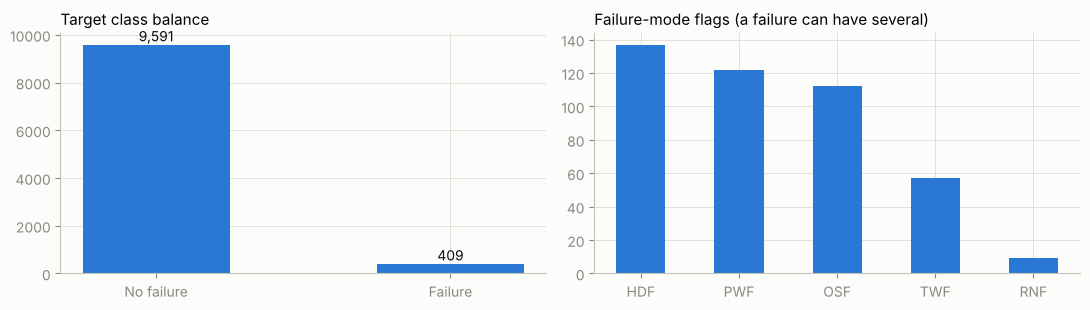

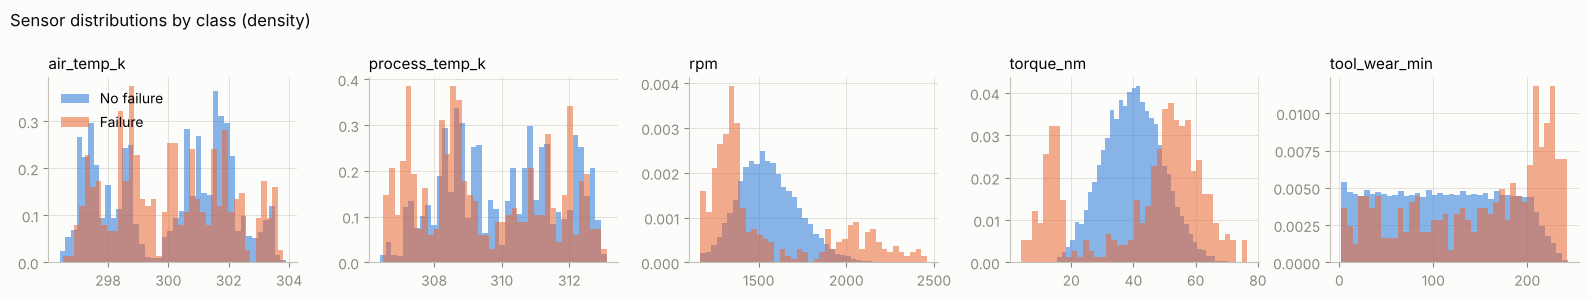

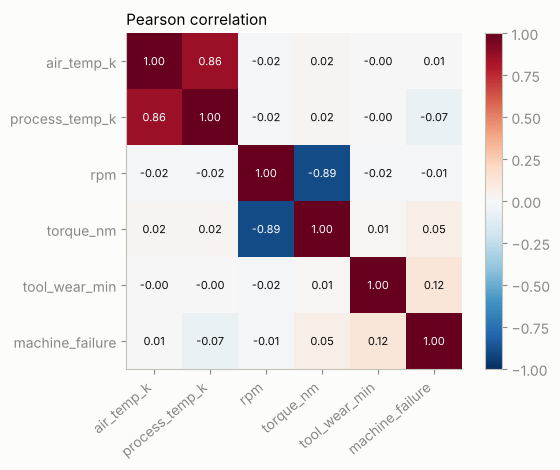

In [4]:
display(raw.describe().T.round(2))
print("Machine failure rate:", f"{raw[TARGET].mean():.2%}")
print("Failure rate by product type:\n", raw.groupby("type")[TARGET].mean().round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
counts = raw[TARGET].value_counts().sort_index()
axes[0].bar(["No failure", "Failure"], counts.values, color=BLUE, width=0.5)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", color=INK)
axes[0].set_title("Target class balance")
modes = raw[FAILURE_MODES].sum().sort_values(ascending=False)
axes[1].bar([m.upper() for m in modes.index], modes.values, color=BLUE, width=0.5)
axes[1].set_title("Failure-mode flags (a failure can have several)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, col in zip(axes, SENSORS):
    for label, color, name in [(0, BLUE, "No failure"), (1, ORANGE, "Failure")]:
        ax.hist(raw.loc[raw[TARGET] == label, col], bins=40, density=True, alpha=0.55, color=color, label=name)
    ax.set_title(col)
axes[0].legend()
plt.suptitle("Sensor distributions by class (density)", x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.show()

corr = raw[SENSORS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if abs(v) > 0.6 else INK)
ax.grid(False); fig.colorbar(im, fraction=0.046); ax.set_title("Pearson correlation")
plt.tight_layout(); plt.show()

## 3 · Data quality

### 3.1 Identifiers and target leakage
`udi` and `product_id` are identifiers (the product-ID letter duplicates `type`). The five failure-mode flags are
recorded **at the same time as** the failure and almost define it, so a model trained on them would score near-perfectly
and be useless in production. All seven columns are removed from the features.

In [5]:
any_mode = raw[FAILURE_MODES].any(axis=1).astype(int)
print("Machine failure vs. 'any failure-mode flag':")
display(pd.crosstab(raw[TARGET], any_mode, rownames=["machine_failure"], colnames=["any mode flag"]))
print("Product-ID prefix equals type:", (raw.product_id.str[0] == raw.type).mean() == 1.0)
print("Duplicate rows (excluding ids):", raw.drop(columns=["udi", "product_id"]).duplicated().sum())
LEAKAGE_AND_IDS = ["udi", "product_id"] + FAILURE_MODES

Machine failure vs. 'any failure-mode flag':


any mode flag,0,1
machine_failure,,
0,9591,0
1,0,409


Product-ID prefix equals type: True
Duplicate rows (excluding ids): 0


### 3.2 Outliers
Values outside 1.5×IQR are counted. They are **kept**: in predictive maintenance the extremes (very high torque, very
low speed) are often exactly the failure signal, and AI4I values are physically plausible. Scaling is applied inside the
pipelines, and tree models are insensitive to monotone scale anyway.

In [6]:
q1, q3 = raw[SENSORS].quantile(0.25), raw[SENSORS].quantile(0.75)
iqr = q3 - q1
outlier = (raw[SENSORS] < q1 - 1.5 * iqr) | (raw[SENSORS] > q3 + 1.5 * iqr)
display(pd.DataFrame({"outliers": outlier.sum(), "share": outlier.mean().round(4),
                      "failure_rate_in_outliers": [raw.loc[outlier[c], TARGET].mean() for c in SENSORS]}).round(4))

,outliers,share,failure_rate_in_outliers
air_temp_k,0,0.0000,NaN
process_temp_k,0,0.0000,NaN
rpm,136,0.0136,0.5000
torque_nm,67,0.0067,0.8209
tool_wear_min,0,0.0000,NaN


### 3.3 Missing values

**Audit first.** The published AI4I file is complete. Real plant data is not: sensors drop out, and historians miss
samples. To make this stage meaningful and to choose an imputation strategy on evidence, we **simulate sensor
drop-outs**: each sensor reading is removed with probability `MISSING_RATE` (missing completely at random). Set
`MISSING_RATE = 0` to skip this.

Because we kept the true values, imputation strategies can be judged two ways:
1. **Reconstruction error**: RMSE between imputed and true values (in standard-deviation units);
2. **Downstream accuracy**: cross-validated PR-AUC of a reference model using each imputer.

Imputers are always fitted **inside** the modelling pipeline on training folds only, so no information leaks from
validation or test rows.

In [7]:
print("Missing values in the source file:\n", raw.isna().sum().to_string())

data = raw.drop(columns=LEAKAGE_AND_IDS).copy()
rng = np.random.default_rng(SEED)
dropout_mask = pd.DataFrame(rng.random((len(data), len(SENSORS))) < MISSING_RATE, columns=SENSORS, index=data.index)
data[SENSORS] = data[SENSORS].mask(dropout_mask)

audit = pd.DataFrame({"missing": data.isna().sum(), "missing_%": (data.isna().mean() * 100).round(2)})
display(audit)
print(f"Rows with at least one missing reading: {data.isna().any(axis=1).mean():.1%}")

Missing values in the source file:
 udi                0
product_id         0
type               0
air_temp_k         0
process_temp_k     0
rpm                0
torque_nm          0
tool_wear_min      0
machine_failure    0
twf                0
hdf                0
pwf                0
osf                0
rnf                0


,missing,missing_%
type,0,0.00
air_temp_k,532,5.32
process_temp_k,492,4.92
rpm,493,4.93
torque_nm,492,4.92
tool_wear_min,488,4.88
machine_failure,0,0.00


Rows with at least one missing reading: 22.6%


## 4 · Train / test split

A stratified 80/20 split keeps the 3.4% failure rate in both parts. **The test set is not used again until Section 11.**
All tuning, comparison and selection happens on the training set with stratified 5-fold cross-validation. The same
folds are reused for every model, so fold scores can be compared pairwise.

In [8]:
X = data[["type"] + SENSORS]
y = data[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
truth_train = raw.loc[X_train.index, SENSORS]          # true values, used only to score imputation quality
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(CV.split(X_train, y_train))
NEG_POS = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Train: {len(X_train):,} rows ({y_train.mean():.2%} failures)   Test: {len(X_test):,} rows ({y_test.mean():.2%} failures)")

Train: 8,000 rows (4.09% failures)   Test: 2,000 rows (4.10% failures)


## 5 · Feature engineering

Domain knowledge from the dataset documentation suggests physically meaningful combinations:

| Feature | Formula | Why |
|---|---|---|
| `temp_diff_k` | process − air temperature | Heat dissipation fails when this gap is small at low speed |
| `power_w` | torque × rpm × 2π / 60 | Power failures happen outside a power band |
| `strain` | tool wear × torque | Overstrain failures depend on this product |
| `strain_ratio` | strain / type-specific overstrain limit | Puts L / M / H machines on one scale |

Then `type` is one-hot encoded and numeric features are standardised. The whole chain (impute → engineer → encode
→ scale → [select] → model) is one scikit-learn `Pipeline`, so it is fitted on training folds only and applied
identically at prediction time.

In [9]:
class PhysicsFeatures(TransformerMixin, BaseEstimator):
    """Adds physics-based features computed from (imputed) sensor readings."""

    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if self.enabled:
            X["temp_diff_k"] = X["process_temp_k"] - X["air_temp_k"]
            X["power_w"] = X["torque_nm"] * X["rpm"] * 2 * np.pi / 60
            X["strain"] = X["tool_wear_min"] * X["torque_nm"]
            X["strain_ratio"] = X["strain"] / X["type"].map(OSF_LIMIT).astype(float)
        return X

    def set_output(self, *, transform=None):
        return self


class ColumnSelector(TransformerMixin, BaseEstimator):
    """Keeps a subset of columns (used by the genetic-algorithm feature selection)."""

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X if self.columns is None else X[list(self.columns)]

    def set_output(self, *, transform=None):
        return self


def make_imputer(strategy: str):
    return {"mean": SimpleImputer(strategy="mean"), "median": SimpleImputer(strategy="median"),
            "knn": KNNImputer(n_neighbors=5), "iterative": IterativeImputer(max_iter=10, random_state=SEED)}[strategy]


def make_preprocessor(imputer="median", engineered=True, columns=None) -> list:
    impute = ColumnTransformer([("num", make_imputer(imputer), SENSORS)], remainder="passthrough",
                               verbose_feature_names_out=False).set_output(transform="pandas")
    encode = ColumnTransformer([("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["type"])],
                               remainder=StandardScaler(), verbose_feature_names_out=False).set_output(transform="pandas")
    return [("impute", impute), ("features", PhysicsFeatures(engineered)), ("encode", encode), ("select", ColumnSelector(columns))]


def make_pipeline(model, imputer="median", engineered=True, columns=None) -> Pipeline:
    return Pipeline(make_preprocessor(imputer, engineered, columns) + [("model", model)])


def cv_pr_auc(pipe) -> np.ndarray:
    return cross_val_score(pipe, X_train, y_train, cv=FOLDS, scoring="average_precision", n_jobs=N_JOBS)


REFERENCE_MODEL = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", min_samples_leaf=2,
                                         n_jobs=1, random_state=SEED)

### 5.1 Choosing the imputation strategy

In [10]:
imputer_rows = []
missing_cells = X_train[SENSORS].isna()
for name in ["mean", "median", "knn", "iterative"]:
    imputed = make_preprocessor(name)[0][1].fit_transform(X_train)
    err = ((imputed[SENSORS] - truth_train) / truth_train.std())[missing_cells]
    rmse = float(np.sqrt(np.nanmean(err.to_numpy() ** 2))) if missing_cells.any().any() else 0.0
    scores = cv_pr_auc(make_pipeline(clone(REFERENCE_MODEL), imputer=name))
    imputer_rows.append({"imputer": name, "rmse_sd_units": rmse, "cv_pr_auc": scores.mean(), "cv_std": scores.std()})
imputer_table = pd.DataFrame(imputer_rows).set_index("imputer").sort_values("cv_pr_auc", ascending=False)
display(imputer_table.round(4))
IMPUTER = imputer_table.index[0]
print(f"Selected imputer: {IMPUTER} (highest CV PR-AUC; reconstruction RMSE shown for reference)")

,rmse_sd_units,cv_pr_auc,cv_std
imputer,,,
median,1.0229,0.8766,0.0100
mean,1.0110,0.8713,0.0108
knn,0.9192,0.8657,0.0127
iterative,0.6535,0.8548,0.0328


Selected imputer: median (highest CV PR-AUC; reconstruction RMSE shown for reference)


### 5.2 Does feature engineering help? (ablation)

In [11]:
ablation = {}
for label, eng in [("raw sensors", False), ("raw + engineered", True)]:
    for mname, model in [("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced")),
                         ("Random Forest", clone(REFERENCE_MODEL))]:
        s = cv_pr_auc(make_pipeline(model, IMPUTER, engineered=eng))
        ablation[(mname, label)] = f"{s.mean():.3f} ± {s.std():.3f}"
display(pd.Series(ablation).unstack().rename_axis(index="model", columns="features (CV PR-AUC)"))

prep = Pipeline(make_preprocessor(IMPUTER))
Z_train = prep.fit_transform(X_train, y_train)          # engineered, encoded, scaled training matrix
FEATURES = list(Z_train.columns)
print("Model input features:", FEATURES)

features (CV PR-AUC),raw + engineered,raw sensors
model,,
Logistic Regression,0.452 ± 0.060,0.115 ± 0.017
Random Forest,0.877 ± 0.010,0.770 ± 0.054


Model input features: ['type_H', 'type_L', 'type_M', 'air_temp_k', 'process_temp_k', 'rpm', 'torque_nm', 'tool_wear_min', 'temp_diff_k', 'power_w', 'strain', 'strain_ratio']


## 6 · Dimensionality reduction & visualisation: PCA (14) and t-SNE (15)

* **PCA** shows how many directions carry the variance. It is also tested as a modelling step (PCA + Logistic
  Regression, tuned number of components) in Section 9.
* **t-SNE** is a non-linear map for visual inspection only (it cannot transform new rows). Its perplexity is tuned by
  **trustworthiness**, which measures how well local neighbourhoods are preserved (1.0 = perfect).

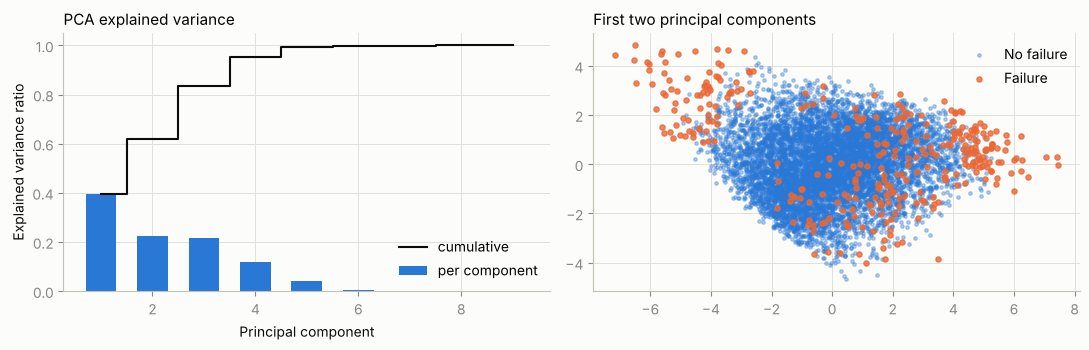

Components for 90% variance: 4 of 9


,trustworthiness
perplexity,
5,0.9899
30,0.9927
50,0.9904


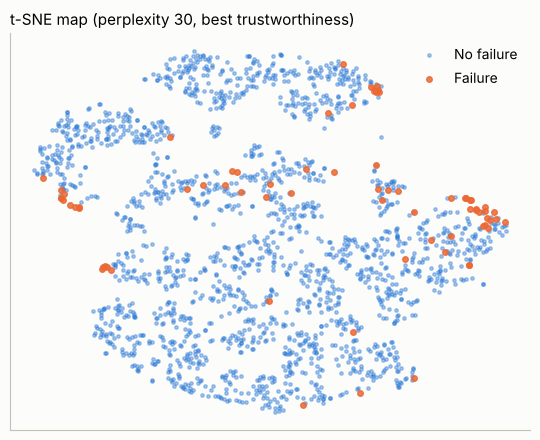

In [12]:
num_cols = [c for c in FEATURES if not c.startswith("type_")]
pca_full = PCA().fit(Z_train[num_cols])
evr = pca_full.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(1, len(evr) + 1), evr, color=BLUE, width=0.6, label="per component")
axes[0].step(range(1, len(evr) + 1), np.cumsum(evr), where="mid", color=INK, linewidth=1.5, label="cumulative")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio"); axes[0].legend()
axes[0].set_title("PCA explained variance")
proj = PCA(2).fit_transform(Z_train[num_cols])
for label, color, name in [(0, BLUE, "No failure"), (1, ORANGE, "Failure")]:
    m = y_train.to_numpy() == label
    axes[1].scatter(proj[m, 0], proj[m, 1], s=6 if label == 0 else 14, alpha=0.35 if label == 0 else 0.8, color=color, label=name)
axes[1].set_title("First two principal components"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Components for 90% variance: {int(np.searchsorted(np.cumsum(evr), 0.90) + 1)} of {len(evr)}")

n_tsne = 800 if FAST_MODE else 2000
idx = np.random.default_rng(SEED).choice(len(Z_train), n_tsne, replace=False)
Zs, ys = Z_train[num_cols].to_numpy()[idx], y_train.to_numpy()[idx]
tsne_rows, embeddings = [], {}
for perp in [5, 30, 50]:
    emb = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEED).fit_transform(Zs)
    embeddings[perp] = emb
    tsne_rows.append({"perplexity": perp, "trustworthiness": trustworthiness(Zs, emb, n_neighbors=10)})
tsne_table = pd.DataFrame(tsne_rows).set_index("perplexity")
best_perp = int(tsne_table.trustworthiness.idxmax())
display(tsne_table.round(4))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
emb = embeddings[best_perp]
for label, color, name in [(0, BLUE, "No failure"), (1, ORANGE, "Failure")]:
    m = ys == label
    ax.scatter(emb[m, 0], emb[m, 1], s=6 if label == 0 else 16, alpha=0.4 if label == 0 else 0.85, color=color, label=name)
ax.set_title(f"t-SNE map (perplexity {best_perp}, best trustworthiness)"); ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 7 · Clustering operating regimes: k-Means (11), K-Means++ (26), Hierarchical (12), DBSCAN (13)

Clustering finds groups of similar operating conditions. Each method's key hyper-parameter is tuned by **silhouette
score** (higher is better), and the methods are compared on silhouette, Davies–Bouldin (lower is better),
Calinski–Harabasz (higher is better) and how differently the clusters fail. Clustering is fitted on numeric training
features only.

* **k-Means (11)** with *random* initialisation vs **K-Means++ (26)** initialisation: same algorithm, different
  seeding. We compare final inertia and iterations over 10 seeds.
* **Hierarchical (12)**: linkage and number of clusters tuned (clusters must hold ≥ 2% of the data, so outlier groups are not mistaken for regimes).
* **DBSCAN (13)**: `eps` and `min_samples` tuned; noise points are reported separately.

mean_inertia            inertia_sd           mean_iterations        silhouette       
init    k-means++     random  k-means++    random       k-means++ random  k-means++ random
k                                                                                         
2       53418.064  53989.622      0.176  1714.639            10.3   10.3      0.233  0.233
3       45198.773  45199.025    447.553   448.424            15.6   18.6      0.208  0.208
4       39162.337  38884.209    879.853   201.925            21.9   20.4      0.216  0.216
5       34944.319  34891.783    419.748   424.400            36.9   47.8      0.213  0.213
6       31814.531  32035.411    276.240   362.115            31.1   37.3      0.228  0.229
7       29292.959  29480.542    362.729   353.648            31.9   36.8      0.221  0.221
8       27043.378  27119.534    151.386   319.011            42.9   41.4      0.220  0.219

,eps,min_samples,clusters,noise,silhouette
0,0.653,5,41,0.506,-0.109
1,0.748,5,20,0.321,-0.230
2,0.807,5,14,0.241,-0.139
3,0.879,5,7,0.162,-0.152
4,0.974,5,3,0.099,-0.131
5,1.157,5,2,0.047,0.178
6,1.336,5,2,0.025,0.137
7,0.794,10,9,0.444,-0.058
8,0.909,10,1,0.256,NaN
9,0.976,10,2,0.183,0.051


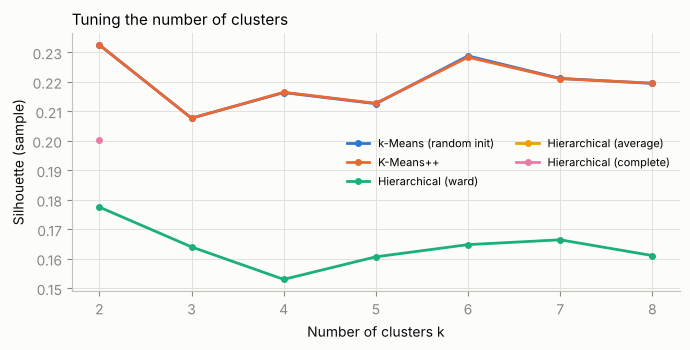

,rank,algorithm,params,clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,failure_rate_range
0,1,13 DBSCAN,"eps=1.06, min_samples=10",2,0.113,0.316,0.627,29.196,0.605
1,2,11 k-Means (random init),k=2,2,0.000,0.233,1.582,1061.593,0.042
2,3,26 K-Means++,k=2,2,0.000,0.233,1.583,1061.508,0.043
3,4,12 Hierarchical,"complete, k=2",2,0.000,0.200,1.669,865.783,0.045


In [13]:
Zc = Z_train[num_cols].to_numpy()
n_sample = 1500 if FAST_MODE else 3000
cidx = np.random.default_rng(SEED + 1).choice(len(Zc), n_sample, replace=False)
Zc_s, yc_s = Zc[cidx], y_train.to_numpy()[cidx]
K_RANGE = range(2, 9)

# k-Means: random init (11) vs k-means++ init (26)
km_rows = []
for k in K_RANGE:
    for init in ["random", "k-means++"]:
        runs = [KMeans(k, init=init, n_init=1, random_state=s).fit(Zc) for s in range(10)]
        best = min(runs, key=lambda r: r.inertia_)
        km_rows.append({"k": k, "init": init, "mean_inertia": np.mean([r.inertia_ for r in runs]),
                        "inertia_sd": np.std([r.inertia_ for r in runs]), "mean_iterations": np.mean([r.n_iter_ for r in runs]),
                        "silhouette": silhouette_score(Zc_s, best.predict(Zc_s))})
km_table = pd.DataFrame(km_rows)
display(km_table.pivot(index="k", columns="init", values=["mean_inertia", "inertia_sd", "mean_iterations", "silhouette"]).round(3))

# Hierarchical (12)
hc_rows = []
for linkage in ["ward", "average", "complete"]:
    for k in K_RANGE:
        lab = AgglomerativeClustering(n_clusters=k, linkage=linkage).fit_predict(Zc_s)
        min_share = np.bincount(lab).min() / len(lab)
        # a "regime" holding < 2% of the data is an outlier group, not an operating regime: exclude it from tuning
        hc_rows.append({"linkage": linkage, "k": k, "min_cluster_share": min_share,
                        "silhouette": silhouette_score(Zc_s, lab) if min_share >= 0.02 else np.nan})
hc_table = pd.DataFrame(hc_rows)

# DBSCAN (13): eps grid from the k-distance distribution
db_rows = []
for min_samples in [5, 10, 20]:
    kdist = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(Zc_s).kneighbors(Zc_s)[0][:, -1])
    for eps in np.quantile(kdist, [0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]):
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Zc_s)
        n_clusters, noise = len(set(lab) - {-1}), float((lab == -1).mean())
        sil = silhouette_score(Zc_s[lab >= 0], lab[lab >= 0]) if n_clusters >= 2 else np.nan
        db_rows.append({"eps": eps, "min_samples": min_samples, "clusters": n_clusters, "noise": noise, "silhouette": sil})
db_table = pd.DataFrame(db_rows)
display(db_table.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
for (lab, data_, col), color in zip([("k-Means (random init)", km_table[km_table.init == "random"], "silhouette"),
                                     ("K-Means++", km_table[km_table.init == "k-means++"], "silhouette")]
                                    + [(f"Hierarchical ({l})", hc_table[hc_table.linkage == l], "silhouette") for l in ["ward", "average", "complete"]],
                                    PALETTE):
    ax.plot(data_.k, data_[col], marker="o", markersize=4, linewidth=2, color=color, label=lab)
ax.set_xlabel("Number of clusters k"); ax.set_ylabel("Silhouette (sample)"); ax.set_title("Tuning the number of clusters")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()


def cluster_report(name, algo_num, labels, params):
    mask = labels >= 0
    n_clusters = int(len(set(labels[mask])))
    rates = pd.Series(yc_s[mask]).groupby(labels[mask]).mean()
    valid = n_clusters >= 2                     # internal indices are undefined for a single cluster
    return {"algorithm": f"{algo_num:02d} {name}", "params": params, "clusters": n_clusters,
            "noise_share": float((~mask).mean()),
            "silhouette": silhouette_score(Zc_s[mask], labels[mask]) if valid else np.nan,
            "davies_bouldin": davies_bouldin_score(Zc_s[mask], labels[mask]) if valid else np.nan,
            "calinski_harabasz": calinski_harabasz_score(Zc_s[mask], labels[mask]) if valid else np.nan,
            "failure_rate_range": float(rates.max() - rates.min()) if len(rates) else np.nan}


best_km = {init: km_table[km_table.init == init].sort_values("silhouette", ascending=False).iloc[0] for init in ["random", "k-means++"]}
best_hc = hc_table.dropna().sort_values("silhouette", ascending=False).iloc[0]
# DBSCAN choice: best silhouette among settings with >= 2 clusters and <= 25% noise. If none exists, the data is one
# dense region at every density level; we then keep the setting with the least noise and report a single cluster.
db_ok = db_table[(db_table.noise <= 0.25) & db_table.silhouette.notna()]
best_db = (db_ok.sort_values("silhouette", ascending=False) if len(db_ok) else db_table.sort_values("noise")).iloc[0]
if not len(db_ok):
    print("DBSCAN: no setting gives >= 2 clusters with <= 25% noise, so the data forms one dense region.")

cluster_rows = []
for init, num, name in [("random", 11, "k-Means (random init)"), ("k-means++", 26, "K-Means++")]:
    k = int(best_km[init].k)
    lab = KMeans(k, init=init, n_init=10, random_state=SEED).fit(Zc).predict(Zc_s)
    cluster_rows.append(cluster_report(name, num, lab, f"k={k}"))
lab = AgglomerativeClustering(n_clusters=int(best_hc.k), linkage=best_hc.linkage).fit_predict(Zc_s)
cluster_rows.append(cluster_report("Hierarchical", 12, lab, f"{best_hc.linkage}, k={int(best_hc.k)}"))
lab = DBSCAN(eps=best_db.eps, min_samples=int(best_db.min_samples)).fit_predict(Zc_s)
cluster_rows.append(cluster_report("DBSCAN", 13, lab, f"eps={best_db.eps:.2f}, min_samples={int(best_db.min_samples)}"))
cluster_leaderboard = pd.DataFrame(cluster_rows).sort_values("silhouette", ascending=False, na_position="last").reset_index(drop=True)
cluster_leaderboard.insert(0, "rank", range(1, len(cluster_leaderboard) + 1))
display(cluster_leaderboard.round(3))

### 7.1 Do regime features help prediction?
The selected K-Means++ model's distances to each cluster centre are appended as features (fitted inside each CV fold)
and compared with the plain pipeline.

In [14]:
class ClusterDistanceFeatures(TransformerMixin, BaseEstimator):
    """Appends distances to K-Means++ centroids fitted on the training fold."""

    def __init__(self, n_clusters=4, random_state=SEED):
        self.n_clusters, self.random_state = n_clusters, random_state

    def fit(self, X, y=None):
        self.cols_ = [c for c in X.columns if not c.startswith("type_")]
        self.km_ = KMeans(self.n_clusters, init="k-means++", n_init=10, random_state=self.random_state).fit(X[self.cols_])
        return self

    def transform(self, X):
        d = self.km_.transform(X[self.cols_])
        return pd.concat([X, pd.DataFrame(d, index=X.index, columns=[f"dist_c{i}" for i in range(self.n_clusters)])], axis=1)

    def set_output(self, *, transform=None):
        return self


K_REGIMES = int(best_km["k-means++"].k)
regime_rows = {}
for mname, model in [("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced")),
                     ("Random Forest", clone(REFERENCE_MODEL))]:
    base = cv_pr_auc(make_pipeline(model, IMPUTER))
    with_reg = cv_pr_auc(Pipeline(make_preprocessor(IMPUTER) + [("regimes", ClusterDistanceFeatures(K_REGIMES)), ("model", clone(model))]))
    regime_rows[mname] = {"without regime features": f"{base.mean():.3f} ± {base.std():.3f}",
                          "with regime features": f"{with_reg.mean():.3f} ± {with_reg.std():.3f}"}
display(pd.DataFrame(regime_rows).T)

,without regime features,with regime features
Logistic Regression,0.452 ± 0.060,0.543 ± 0.046
Random Forest,0.877 ± 0.010,0.864 ± 0.003


## 8 · Feature selection with a Genetic Algorithm (30)

Each chromosome is a bit-mask over the model input features. Fitness = 3-fold CV PR-AUC of a Random Forest on the
selected features, minus a small penalty per feature (favours simpler models). The GA uses tournament selection,
single-point crossover, bit-flip mutation and elitism. It runs on the training set only. The selected subset becomes
the candidate model "30 GA-selected features + Random Forest" in Section 9.

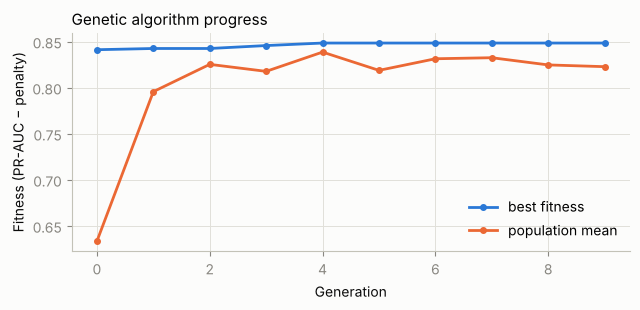

Evaluated 88 distinct subsets. Selected 9/12 features: ['type_L', 'air_temp_k', 'process_temp_k', 'rpm', 'tool_wear_min', 'temp_diff_k', 'power_w', 'strain', 'strain_ratio']
Fitness — all features: 0.8349   GA selection: 0.8484


In [15]:
GA_POP, GA_GENS = (8, 4) if FAST_MODE else (16, 10)
GA_PENALTY, GA_MUTATION, GA_ELITE = 0.002, 1.0 / len(FEATURES), 2
ga_rng = np.random.default_rng(SEED)
ga_cache: dict[tuple, float] = {}
GA_FOLDS = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Z_train, y_train))


def ga_fitness(mask: np.ndarray) -> float:
    key = tuple(int(b) for b in mask)
    if key not in ga_cache:
        if mask.sum() == 0:
            ga_cache[key] = 0.0
        else:
            cols = [f for f, b in zip(FEATURES, mask) if b]
            rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", min_samples_leaf=2,
                                        n_jobs=N_JOBS, random_state=SEED)
            s = cross_val_score(rf, Z_train[cols], y_train, cv=GA_FOLDS, scoring="average_precision").mean()
            ga_cache[key] = s - GA_PENALTY * mask.sum()
    return ga_cache[key]


def tournament(pop, fit, k=3):
    idx = ga_rng.choice(len(pop), k, replace=False)
    return pop[idx[np.argmax(fit[idx])]]


population = ga_rng.integers(0, 2, (GA_POP, len(FEATURES)))
population[0] = 1                                     # include the all-features solution
ga_history = []
for gen in range(GA_GENS):
    fitness = np.array([ga_fitness(ind) for ind in population])
    ga_history.append({"generation": gen, "best": fitness.max(), "mean": fitness.mean()})
    elite = population[np.argsort(fitness)[-GA_ELITE:]]
    children = []
    while len(children) < GA_POP - GA_ELITE:
        a, b = tournament(population, fitness), tournament(population, fitness)
        cut = ga_rng.integers(1, len(FEATURES))
        child = np.r_[a[:cut], b[cut:]]
        flip = ga_rng.random(len(FEATURES)) < GA_MUTATION
        children.append(np.where(flip, 1 - child, child))
    population = np.vstack([elite] + children)
fitness = np.array([ga_fitness(ind) for ind in population])
best_mask = population[fitness.argmax()]
GA_FEATURES = [f for f, b in zip(FEATURES, best_mask) if b]

hist = pd.DataFrame(ga_history)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(hist.generation, hist.best, marker="o", markersize=4, linewidth=2, color=BLUE, label="best fitness")
ax.plot(hist.generation, hist["mean"], marker="o", markersize=4, linewidth=2, color=ORANGE, label="population mean")
ax.set_xlabel("Generation"); ax.set_ylabel("Fitness (PR-AUC − penalty)"); ax.set_title("Genetic algorithm progress"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Evaluated {len(ga_cache)} distinct subsets. Selected {len(GA_FEATURES)}/{len(FEATURES)} features: {GA_FEATURES}")
print(f"Fitness — all features: {ga_fitness(np.ones(len(FEATURES), int)):.4f}   GA selection: {fitness.max():.4f}")

## 9 · Model training and hyper-parameter tuning

Every candidate is the **same preprocessing pipeline + a different model**, tuned with `RandomizedSearchCV` on the
5 shared stratified folds, optimising **PR-AUC** (average precision). PR-AUC is the right headline metric for a 3%
positive class, where accuracy and even ROC-AUC look flattering.

Class imbalance is handled with class weights where the algorithm supports them (`class_weight="balanced"`,
XGBoost's `scale_pos_weight`, `pos_weight` in the PyTorch loss). Decision thresholds are tuned later from out-of-fold
predictions (Section 10).

Notes on how some algorithms are used for failure prediction:
* **1 Linear Regression** is fitted by least squares on the 0/1 label (a *linear probability model*), with an optional
  ridge penalty. Its output is a risk score.
* **22 CNN, 23 RNN, 24 LSTM, 25 Transformer**: AI4I rows are independent snapshots, not time series, so these networks
  read each row's features as a **sequence of feature tokens** (each scaled value is embedded together with a learned
  feature-identity embedding, as in FT-Transformer). This is a recognised approach for tabular data, but it is not
  where these architectures shine. Expect tree ensembles to win here.
* **27 Autoencoder** (trained on normal rows only) and **28 Isolation Forest** (unsupervised) are *anomaly detectors*:
  their anomaly score is used as a failure-risk score. Labels are used only for tuning and thresholding.

In [16]:
class LinearRegressionClassifier(ClassifierMixin, BaseEstimator):
    """Least squares on the 0/1 target (linear probability model); alpha > 0 adds a ridge penalty."""

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.reg_ = (LinearRegression() if self.alpha == 0 else Ridge(alpha=self.alpha)).fit(X, y)
        return self

    def decision_function(self, X):
        return self.reg_.predict(X)

    def predict(self, X):
        return (self.decision_function(X) >= 0.5).astype(int)


class IsolationForestScorer(ClassifierMixin, BaseEstimator):
    """Unsupervised Isolation Forest; anomaly score = failure-risk score. Labels only set the alert rate."""

    def __init__(self, n_estimators=200, max_samples="auto", max_features=1.0, random_state=SEED):
        self.n_estimators, self.max_samples, self.max_features, self.random_state = n_estimators, max_samples, max_features, random_state

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.forest_ = IsolationForest(n_estimators=self.n_estimators, max_samples=self.max_samples,
                                       max_features=self.max_features, random_state=self.random_state, n_jobs=1).fit(np.asarray(X, float))
        self.threshold_ = np.quantile(self.decision_function(X), 1 - np.mean(y))
        return self

    def decision_function(self, X):
        return -self.forest_.score_samples(np.asarray(X, float))

    def predict(self, X):
        return (self.decision_function(X) >= self.threshold_).astype(int)


class AutoencoderScorer(ClassifierMixin, BaseEstimator):
    """Autoencoder trained to reconstruct normal rows; reconstruction error = failure-risk score."""

    def __init__(self, hidden=16, bottleneck=3, alpha=1e-4, random_state=SEED):
        self.hidden, self.bottleneck, self.alpha, self.random_state = hidden, bottleneck, alpha, random_state

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        X = np.asarray(X, float)
        normal = X[np.asarray(y) == 0]
        self.ae_ = MLPRegressor(hidden_layer_sizes=(self.hidden, self.bottleneck, self.hidden), activation="tanh",
                                alpha=self.alpha, max_iter=400, early_stopping=True, random_state=self.random_state).fit(normal, normal)
        self.threshold_ = np.quantile(self.decision_function(X), 1 - np.mean(y))
        return self

    def decision_function(self, X):
        X = np.asarray(X, float)
        return ((X - self.ae_.predict(X)) ** 2).mean(axis=1)

    def predict(self, X):
        return (self.decision_function(X) >= self.threshold_).astype(int)


if TORCH:
    class FeatureTokenNet(nn.Module):
        """Embeds each feature value as a token, then applies a CNN / RNN / LSTM / Transformer body."""

        def __init__(self, arch: str, n_features: int, d: int, dropout: float):
            super().__init__()
            self.arch = arch
            self.value_proj = nn.Linear(1, d)
            self.feature_emb = nn.Parameter(torch.randn(n_features, d) * 0.02)
            if arch == "cnn":
                self.body = nn.Sequential(nn.Conv1d(d, d, 3, padding=1), nn.ReLU(), nn.Conv1d(d, d, 3, padding=1), nn.ReLU())
            elif arch == "rnn":
                self.body = nn.RNN(d, d, batch_first=True)
            elif arch == "lstm":
                self.body = nn.LSTM(d, d, batch_first=True)
            elif arch == "transformer":
                self.cls = nn.Parameter(torch.zeros(1, 1, d))
                layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=2 * d, dropout=dropout, batch_first=True)
                self.body = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
            else:
                raise ValueError(arch)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, 1))

        def forward(self, x):
            tokens = self.value_proj(x.unsqueeze(-1)) + self.feature_emb           # (batch, features, d)
            if self.arch == "cnn":
                h = self.body(tokens.transpose(1, 2)).amax(dim=2)
            elif self.arch in ("rnn", "lstm"):
                h = self.body(tokens)[0][:, -1]
            else:
                h = self.body(torch.cat([self.cls.expand(len(x), -1, -1), tokens], dim=1))[:, 0]
            return self.head(h).squeeze(-1)


class TorchTabularClassifier(ClassifierMixin, BaseEstimator):
    """scikit-learn wrapper so PyTorch models go through the same pipeline, tuning and CV as everything else."""

    def __init__(self, arch="transformer", d_model=32, lr=3e-3, dropout=0.1, epochs=30, batch_size=256, random_state=SEED):
        self.arch, self.d_model, self.lr, self.dropout = arch, d_model, lr, dropout
        self.epochs, self.batch_size, self.random_state = epochs, batch_size, random_state

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        self.classes_ = np.array([0, 1])
        Xt = torch.tensor(np.asarray(X, np.float32))
        yt = torch.tensor(np.asarray(y, np.float32))
        self.net_ = FeatureTokenNet(self.arch, Xt.shape[1], self.d_model, self.dropout)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=1e-4)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - yt.mean()) / yt.mean().clamp(min=1e-6)))
        gen = torch.Generator().manual_seed(self.random_state)
        self.net_.train()
        for _ in range(self.epochs):
            for batch in torch.randperm(len(Xt), generator=gen).split(self.batch_size):
                opt.zero_grad()
                loss_fn(self.net_(Xt[batch]), yt[batch]).backward()
                opt.step()
        self.net_.eval()
        return self

    def decision_function(self, X):
        with torch.no_grad():
            return self.net_(torch.tensor(np.asarray(X, np.float32))).numpy()

    def predict_proba(self, X):
        p = 1 / (1 + np.exp(-self.decision_function(X)))
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def risk_score(est, X) -> np.ndarray:
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

In [17]:
C = loguniform(1e-3, 1e2)
CANDIDATES = {   # algorithm number: (name, model, search space, extra pipeline options)
    1: ("Linear Regression", LinearRegressionClassifier(), {"model__alpha": [0.0, 0.1, 1.0, 10.0, 100.0]}, {}),
    2: ("Logistic Regression", LogisticRegression(max_iter=3000, class_weight="balanced", solver="liblinear"),
        {"model__C": C, "model__penalty": ["l1", "l2"]}, {}),
    3: ("Decision Tree", DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"model__max_depth": [3, 4, 5, 6, 8, 10, 14, None], "model__min_samples_leaf": [1, 2, 5, 10, 20, 40],
         "model__criterion": ["gini", "entropy"]}, {}),
    4: ("Random Forest", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
        {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 8, 12, 16],
         "model__min_samples_leaf": [1, 2, 4, 8], "model__max_features": ["sqrt", 0.5, None]}, {}),
    5: ("Support Vector Machine", SVC(kernel="rbf", class_weight="balanced"),
        {"model__C": loguniform(0.1, 100), "model__gamma": loguniform(1e-3, 1)}, {}),
    6: ("k-Nearest Neighbors", KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 11, 15, 21, 31], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}, {}),
    7: ("Naive Bayes", GaussianNB(), {"model__var_smoothing": loguniform(1e-12, 1e-2)}, {}),
    8: ("Gradient Boosting", GradientBoostingClassifier(random_state=SEED),
        {"model__n_estimators": [100, 200, 300], "model__learning_rate": loguniform(0.02, 0.3),
         "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.85, 1.0]}, {}),
    9: ("AdaBoost", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=SEED),
        {"model__n_estimators": [100, 200, 400], "model__learning_rate": loguniform(0.05, 1.0),
         "model__estimator__max_depth": [1, 2, 3]}, {}),
    10: ("XGBoost", XGBClassifier(scale_pos_weight=NEG_POS, tree_method="hist", eval_metric="logloss", n_jobs=1, random_state=SEED),
         {"model__n_estimators": [200, 400, 600], "model__learning_rate": loguniform(0.02, 0.3),
          "model__max_depth": [3, 4, 5, 6], "model__subsample": [0.7, 0.85, 1.0], "model__colsample_bytree": [0.6, 0.8, 1.0],
          "model__min_child_weight": [1, 3, 5], "model__reg_lambda": loguniform(0.1, 10)}, {}),
    14: ("PCA + Logistic Regression", Pipeline([("pca", PCA(random_state=SEED)),
                                                ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
         {"model__pca__n_components": [2, 3, 4, 6, 8, 10], "model__clf__C": C}, {}),
    21: ("Artificial Neural Network", MLPClassifier(max_iter=600, early_stopping=True, random_state=SEED),
         {"model__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "model__alpha": loguniform(1e-5, 1e-2),
          "model__learning_rate_init": loguniform(1e-4, 1e-2)}, {}),
    27: ("Autoencoder", AutoencoderScorer(),
         {"model__hidden": [8, 16, 32], "model__bottleneck": [2, 3, 4, 6], "model__alpha": loguniform(1e-5, 1e-2)}, {}),
    28: ("Isolation Forest", IsolationForestScorer(),
         {"model__n_estimators": [100, 200, 400], "model__max_samples": [128, 256, 512, 1024],
          "model__max_features": [0.5, 0.75, 1.0]}, {}),
    30: ("GA-selected features + Random Forest", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
         {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 8, 12, 16],
          "model__min_samples_leaf": [1, 2, 4, 8], "model__max_features": ["sqrt", 0.5, None]}, {"columns": GA_FEATURES}),
}
if TORCH:
    dl_space = {"model__d_model": [16, 32], "model__lr": loguniform(1e-3, 1e-2), "model__dropout": [0.0, 0.1, 0.2]}
    for num, name, arch in [(22, "Convolutional Neural Network", "cnn"), (23, "Recurrent Neural Network", "rnn"),
                            (24, "Long Short-Term Memory", "lstm"), (25, "Transformer", "transformer")]:
        CANDIDATES[num] = (name, TorchTabularClassifier(arch=arch, epochs=DL_EPOCHS), dl_space, {"dl": True})
print(f"{len(CANDIDATES)} candidate models")

19 candidate models


In [18]:
search_results = {}
for num in sorted(CANDIDATES):
    name, model, space, opts = CANDIDATES[num]
    pipe = make_pipeline(clone(model), IMPUTER, columns=opts.get("columns"))
    dl = opts.get("dl", False)
    t0 = time.perf_counter()
    search = RandomizedSearchCV(pipe, space, n_iter=DL_N_ITER if dl else N_ITER, scoring="average_precision", cv=FOLDS,
                                n_jobs=1 if dl else N_JOBS, random_state=SEED, refit=True, error_score=np.nan)
    search.fit(X_train, y_train)
    bi = search.best_index_
    search_results[num] = {
        "name": name, "search": search, "tune_seconds": time.perf_counter() - t0,
        "fold_scores": np.array([search.cv_results_[f"split{i}_test_score"][bi] for i in range(CV_FOLDS)]),
        "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    }
    s = search_results[num]["fold_scores"]
    print(f"{num:02d} {name:38s} CV PR-AUC {s.mean():.4f} ± {s.std():.4f}   ({search_results[num]['tune_seconds']:.0f}s)")

01 Linear Regression                      CV PR-AUC 0.4696 ± 0.0699   (0s)


02 Logistic Regression                    CV PR-AUC 0.4550 ± 0.0659   (10s)


03 Decision Tree                          CV PR-AUC 0.8356 ± 0.0172   (3s)


04 Random Forest                          CV PR-AUC 0.8817 ± 0.0081   (113s)


05 Support Vector Machine                 CV PR-AUC 0.6901 ± 0.0224   (26s)


...

24 Long Short-Term Memory                 CV PR-AUC 0.7281 ± 0.0352   (158s)


25 Transformer                            CV PR-AUC 0.7541 ± 0.0137   (866s)


27 Autoencoder                            CV PR-AUC 0.3201 ± 0.0452   (107s)


28 Isolation Forest                       CV PR-AUC 0.4796 ± 0.0416   (21s)


30 GA-selected features + Random Forest   CV PR-AUC 0.8797 ± 0.0090   (104s)


## 10 · Model validation and comparison

For each tuned model:

* **CV PR-AUC** (mean ± sd over the 5 folds) from the tuning run.
* **Out-of-fold (OOF) predictions**: the tuned configuration is re-trained on 4 folds and scores the 5th, so every
  training row gets an honest prediction. From these we compute ROC-AUC, F1, recall, precision, MCC, balanced
  accuracy, and the **cost-optimal threshold**, the one that minimises `COST_FN × missed failures + COST_FP × false alarms`.
* **Corrected resampled paired t-test** (Nadeau & Bengio, 2003) of each model's fold scores against the best model.
  It accounts for the overlap between CV training sets. Models with p ≥ 0.05 are *statistically tied* with the best.

,rank,model,cv_pr_auc,cv_sd,oof_roc_auc,oof_f1,oof_recall,oof_precision,oof_mcc,oof_cost_per_1000,tune_seconds,p_vs_best,tied_with_best
0,1,08 Gradient Boosting,0.8859,0.0092,0.9786,0.6251,0.9052,0.4774,0.6390,13825.00,80.3788,1.0000,True
1,2,09 AdaBoost,0.8849,0.0116,0.9782,0.6599,0.8991,0.5213,0.6682,13312.50,112.9678,0.8608,True
2,3,04 Random Forest,0.8817,0.0081,0.9739,0.7291,0.8685,0.6283,0.7260,13900.00,113.0319,0.4949,True
3,4,10 XGBoost,0.8797,0.0162,0.9771,0.6974,0.8777,0.5786,0.6983,13918.75,12.6767,0.6818,True
4,5,30 GA-selected features + Random Forest,0.8797,0.0090,0.9755,0.7145,0.8685,0.6068,0.7125,14200.00,104.2658,0.4286,True
5,6,03 Decision Tree,0.8356,0.0172,0.9465,0.6870,0.8624,0.5709,0.6867,15225.00,2.7270,0.0077,False
6,7,25 Transformer,0.7541,0.0137,0.9596,0.4812,0.9205,0.3258,0.5199,18181.25,866.1221,0.0010,False
7,8,23 Recurrent Neural Network,0.7413,0.0244,0.9591,0.5280,0.8807,0.3770,0.5515,18675.00,153.2457,0.0017,False
8,9,22 Convolutional Neural Network,0.7340,0.0319,0.9557,0.4987,0.8716,0.3493,0.5249,20456.25,189.5587,0.0024,False
9,10,24 Long Short-Term Memory,0.7281,0.0352,0.9464,0.5984,0.8043,0.4764,0.5989,21418.75,158.2387,0.0037,False


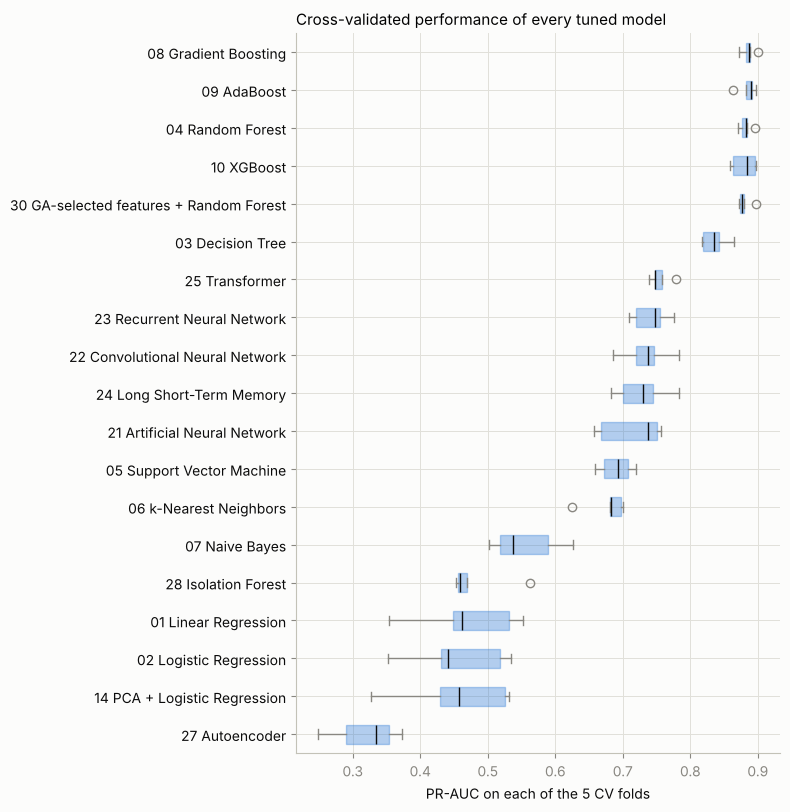

In [19]:
def oof_scores(estimator) -> np.ndarray:
    oof = np.zeros(len(X_train))
    for tr, va in FOLDS:
        m = clone(estimator).fit(X_train.iloc[tr], y_train.iloc[tr])
        oof[va] = risk_score(m, X_train.iloc[va])
    return oof


def cost_optimal_threshold(y_true, scores):
    cands = np.unique(np.quantile(scores, np.linspace(0, 1, 2001)))
    costs = [COST_FN * np.sum((scores < t) & (y_true == 1)) + COST_FP * np.sum((scores >= t) & (y_true == 0)) for t in cands]
    i = int(np.argmin(costs))
    return float(cands[i]), float(costs[i])


def classification_metrics(y_true, scores, threshold) -> dict:
    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"pr_auc": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores),
            "f1": f1_score(y_true, pred, zero_division=0), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "mcc": matthews_corrcoef(y_true, pred),
            "balanced_acc": balanced_accuracy_score(y_true, pred),
            "cost_per_1000": (COST_FN * fn + COST_FP * fp) / len(y_true) * 1000, "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / math.sqrt((1 / k + n_test / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), k - 1)


rows = []
for num, r in search_results.items():
    oof = oof_scores(r["search"].best_estimator_)
    thr, _ = cost_optimal_threshold(y_train.to_numpy(), oof)
    r["oof"], r["threshold"] = oof, thr
    m = classification_metrics(y_train.to_numpy(), oof, thr)
    rows.append({"num": num, "model": f"{num:02d} {r['name']}", "cv_pr_auc": r["fold_scores"].mean(),
                 "cv_sd": r["fold_scores"].std(), "oof_roc_auc": m["roc_auc"], "oof_f1": m["f1"], "oof_recall": m["recall"],
                 "oof_precision": m["precision"], "oof_mcc": m["mcc"], "oof_cost_per_1000": m["cost_per_1000"],
                 "tune_seconds": r["tune_seconds"]})
leaderboard = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
best_num = int(leaderboard.num.iloc[0])
n_tr = len(X_train) * (CV_FOLDS - 1) / CV_FOLDS
n_te = len(X_train) / CV_FOLDS
pvals = [corrected_ttest(search_results[best_num]["fold_scores"], search_results[n]["fold_scores"], n_tr, n_te)[1]
         if n != best_num else 1.0 for n in leaderboard.num]
leaderboard["p_vs_best"] = pvals
leaderboard["tied_with_best"] = leaderboard.p_vs_best >= 0.05
leaderboard.insert(0, "rank", range(1, len(leaderboard) + 1))
display(leaderboard.drop(columns="num").round(4))

order = leaderboard.num.tolist()[::-1]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(order) + 1))
ax.boxplot([search_results[n]["fold_scores"] for n in order], vert=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor=BLUE, color=BLUE, alpha=0.35), medianprops=dict(color=INK), whiskerprops=dict(color=MUTED),
           capprops=dict(color=MUTED), flierprops=dict(markeredgecolor=MUTED))
ax.set_yticks(range(1, len(order) + 1), [f"{n:02d} {search_results[n]['name']}" for n in order], color=INK)
ax.set_xlabel("PR-AUC on each of the 5 CV folds"); ax.set_title("Cross-validated performance of every tuned model")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "cv_comparison.png", dpi=150); plt.show()

## 11 · Model selection and final test evaluation

**Selection rule (decided before looking at the test set):** among the models statistically tied with the best CV
PR-AUC, choose the one with the **lowest out-of-fold operating cost** at its cost-optimal threshold; break remaining
ties by shorter training time. This prefers a model that is as accurate as the best and cheaper to run in the plant.

The selected pipeline, already re-fitted on the full training set, is then scored **once** on the untouched test set.
All other models' test scores are shown afterwards for transparency only; they played no part in the choice.

Statistically tied with the best: 09 AdaBoost, 08 Gradient Boosting, 04 Random Forest, 10 XGBoost, 30 GA-selected features + Random Forest
SELECTED: 09 AdaBoost
  hyper-parameters: {'estimator__max_depth': 3, 'learning_rate': np.float64(0.0833349164303321), 'n_estimators': 400}
  decision threshold: 0.3689


,test set — AdaBoost
pr_auc,0.7687
roc_auc,0.9405
f1,0.5728
precision,0.4656
recall,0.7439
mcc,0.5670
balanced_acc,0.8537
cost_per_1000,26250.0000
tp,61.0000
fp,70.0000


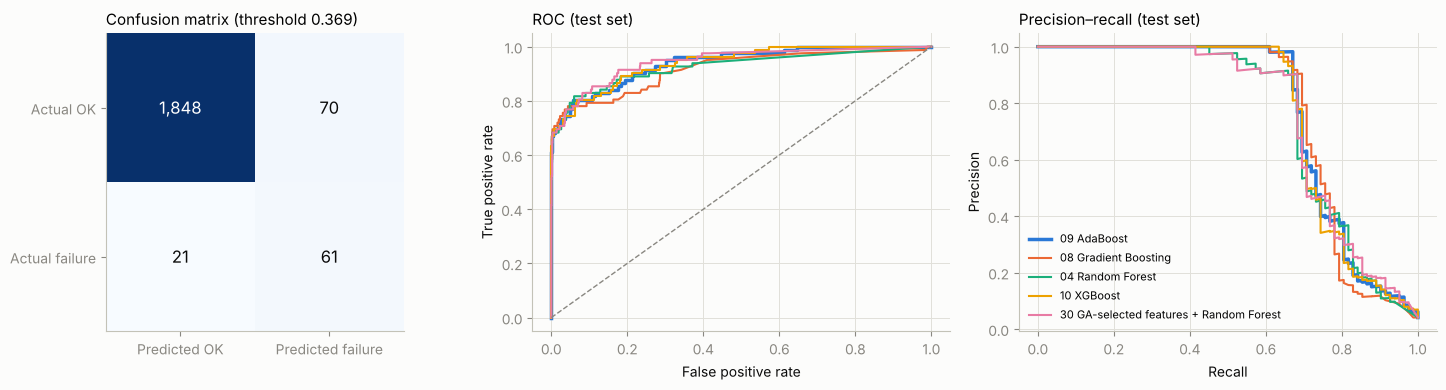

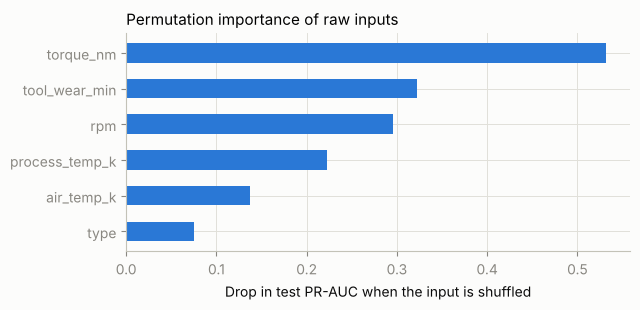

Test-set scores of all models (for transparency; not used for selection):


,model,pr_auc,roc_auc,f1,precision,recall,cost_per_1000
0,09 AdaBoost,0.7687,0.9405,0.5728,0.4656,0.7439,26250.0
1,08 Gradient Boosting,0.7657,0.9174,0.5289,0.4000,0.7805,25200.0
2,10 XGBoost,0.7627,0.9403,0.5545,0.4420,0.7439,26775.0
3,30 GA-selected features + Random Forest,0.7556,0.9441,0.6105,0.5370,0.7073,27750.0
4,04 Random Forest,0.7530,0.9258,0.6196,0.5588,0.6951,28375.0
5,03 Decision Tree,0.7263,0.8902,0.6322,0.5978,0.6707,29775.0
6,24 Long Short-Term Memory,0.6878,0.9113,0.5600,0.4746,0.6829,30650.0
7,25 Transformer,0.6729,0.9252,0.4317,0.2918,0.8293,26375.0
8,22 Convolutional Neural Network,0.6542,0.9358,0.4555,0.3216,0.7805,28125.0
9,23 Recurrent Neural Network,0.6386,0.9223,0.4555,0.3216,0.7805,28125.0


Saved the selected pipeline to models/failure_model.joblib


In [20]:
tied = leaderboard[leaderboard.tied_with_best].sort_values(["oof_cost_per_1000", "tune_seconds"])
SELECTED = int(tied.num.iloc[0])
sel = search_results[SELECTED]
final_model = sel["search"].best_estimator_
print(f"Statistically tied with the best: {', '.join(tied.model)}")
print(f"SELECTED: {SELECTED:02d} {sel['name']}\n  hyper-parameters: {sel['best_params']}\n  decision threshold: {sel['threshold']:.4f}")

test_scores = risk_score(final_model, X_test)
test_metrics = classification_metrics(y_test.to_numpy(), test_scores, sel["threshold"])
display(pd.Series({k: v for k, v in test_metrics.items()}).to_frame(f"test set — {sel['name']}").round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cm = confusion_matrix(y_test, (test_scores >= sel["threshold"]).astype(int))
axes[0].imshow(cm, cmap="Blues"); axes[0].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f"{v:,}", ha="center", va="center", color="#ffffff" if v > cm.max() / 2 else INK, fontsize=12)
axes[0].set_xticks([0, 1], ["Predicted OK", "Predicted failure"]); axes[0].set_yticks([0, 1], ["Actual OK", "Actual failure"])
axes[0].set_title(f"Confusion matrix (threshold {sel['threshold']:.3f})")
top = [SELECTED] + [n for n in leaderboard.num if n != SELECTED][:4]
for n, color in zip(top, PALETTE):
    s = risk_score(search_results[n]["search"].best_estimator_, X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    lw = 2.5 if n == SELECTED else 1.5
    axes[1].plot(fpr, tpr, color=color, linewidth=lw, label=f"{n:02d} {search_results[n]['name']}")
    axes[2].plot(rec, prec, color=color, linewidth=lw, label=f"{n:02d} {search_results[n]['name']}")
axes[1].plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC (test set)")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision–recall (test set)")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "test_evaluation.png", dpi=150); plt.show()

pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=N_JOBS)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(imp.index, imp.values, color=BLUE, height=0.55)
ax.set_xlabel("Drop in test PR-AUC when the input is shuffled"); ax.set_title("Permutation importance of raw inputs")
plt.tight_layout(); plt.show()

all_test = pd.DataFrame([{"model": f"{n:02d} {r['name']}",
                          **{k: v for k, v in classification_metrics(y_test.to_numpy(), risk_score(r["search"].best_estimator_, X_test), r["threshold"]).items()
                             if k in ("pr_auc", "roc_auc", "f1", "recall", "precision", "cost_per_1000")}}
                         for n, r in search_results.items()]).sort_values("pr_auc", ascending=False)
print("Test-set scores of all models (for transparency; not used for selection):")
display(all_test.round(4).reset_index(drop=True))

joblib.dump({"pipeline": final_model, "threshold": sel["threshold"], "model": sel["name"], "params": sel["best_params"]},
            MODEL_DIR / "failure_model.joblib")
print(f"Saved the selected pipeline to {MODEL_DIR / 'failure_model.joblib'}")

## 12 · Maintenance decision optimisation: MDP (29), Q-Learning (16), SARSA (17), DQN (18), Policy Gradient (19), Actor-Critic (20)

Predicting failure is half the job. The other half is deciding **when to replace the tool**. We build a simulator from
the training data:

* **State**: tool-wear bucket (`WEAR_BUCKET` minutes each).
* **Actions**: `run` one production cycle, or `replace` the tool.
* **Dynamics**: running earns `REVENUE`, wears the tool by one bucket, and fails with the probability observed in the
  training data for that wear bucket (Laplace-smoothed). A failure costs `FAILURE_COST` and resets the tool.
  Replacing costs `REPLACE_COST` and resets the tool.

Assumption: the per-bucket failure share in AI4I snapshots is used as a per-cycle failure hazard. That is a
simplification, so tune the economics to your plant.

* **29 MDP / value iteration** knows the transition model and computes the **optimal** policy, the benchmark.
* **16 Q-Learning, 17 SARSA** (tabular), **18 DQN, 19 Policy Gradient (REINFORCE), 20 Actor-Critic** (neural, PyTorch)
  learn only by interacting with the simulator. Each learner's key hyper-parameter is tuned on validation episodes, and
  the final policies are compared on separate test episodes. Two rule-based baselines are included: run-to-failure,
  and replace at ≥ 200 min (from the dataset's tool-wear failure description).

In [21]:
WEAR_BUCKET = 20
REVENUE, FAILURE_COST, REPLACE_COST = 100.0, 2000.0, 300.0
GAMMA, EPISODE_LEN = 0.97, 100
N_STATES = int(math.ceil((raw.tool_wear_min.max() + 1) / WEAR_BUCKET))
RUN, REPLACE = 0, 1

train_rows = raw.loc[X_train.index]
bucket = (train_rows.tool_wear_min // WEAR_BUCKET).clip(upper=N_STATES - 1).astype(int)
grp = train_rows.groupby(bucket)[TARGET].agg(["sum", "count"]).reindex(range(N_STATES), fill_value=0)
P_FAIL = ((grp["sum"] + 1) / (grp["count"] + 2)).to_numpy()
display(pd.DataFrame({"wear_from_min": np.arange(N_STATES) * WEAR_BUCKET, "rows": grp["count"].to_numpy(),
                      "failure_probability": P_FAIL.round(4)}).T)


class MaintenanceEnv:
    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.s, self.t = 0, 0
        return self.s

    def step(self, a):
        self.t += 1
        if a == REPLACE:
            self.s, r, failed = 0, -REPLACE_COST, False
        elif self.rng.random() < P_FAIL[self.s]:
            self.s, r, failed = 0, REVENUE - FAILURE_COST, True
        else:
            self.s, r, failed = min(self.s + 1, N_STATES - 1), REVENUE, False
        return self.s, r, self.t >= EPISODE_LEN, failed


def evaluate_policy(policy: np.ndarray, seeds) -> dict:
    totals, fails, repl = [], 0, 0
    for sd in seeds:
        env, total = MaintenanceEnv(sd), 0.0
        s, done = env.reset(), False
        while not done:
            a = int(policy[s])
            s, r, done, failed = env.step(a)
            total, fails, repl = total + r, fails + failed, repl + (a == REPLACE)
        totals.append(total)
    cycles = len(seeds) * EPISODE_LEN
    return {"mean_reward": float(np.mean(totals)), "sd_reward": float(np.std(totals)),
            "failures_per_1000": fails / cycles * 1000, "replacements_per_1000": repl / cycles * 1000}


VAL_SEEDS, TEST_SEEDS = range(10_000, 10_100), range(20_000, 20_300)
EPISODES = {"tabular": 1500 if FAST_MODE else 4000, "dqn": 120 if FAST_MODE else 300,
            "pg": 300 if FAST_MODE else 800, "ac": 200 if FAST_MODE else 500}

,0,1,2,3,4,5,6,7,8,9,10,11,12
wear_from_min,0.0000,20.0000,40.0000,60.0000,80.00,100.0000,120.0000,140.0000,160.0000,180.0000,200.0000,220.00,240.0000
rows,646.0000,743.0000,743.0000,734.0000,731.00,754.0000,701.0000,723.0000,738.0000,690.0000,570.0000,218.00,9.0000
failure_probability,0.0247,0.0322,0.0242,0.0299,0.03,0.0265,0.0284,0.0276,0.0284,0.0477,0.1066,0.25,0.7273


In [22]:
# 29 MDP: value iteration on the known model
def value_iteration(tol=1e-8):
    V = np.zeros(N_STATES)
    nxt = np.minimum(np.arange(N_STATES) + 1, N_STATES - 1)
    while True:
        q_run = P_FAIL * (REVENUE - FAILURE_COST + GAMMA * V[0]) + (1 - P_FAIL) * (REVENUE + GAMMA * V[nxt])
        q_rep = -REPLACE_COST + GAMMA * V[0]
        V_new = np.maximum(q_run, q_rep)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new, np.where(q_rep > q_run, REPLACE, RUN)
        V = V_new


V_OPT, POLICY_OPT = value_iteration()


# 16 Q-Learning and 17 SARSA (tabular, epsilon-greedy with linear decay)
def train_tabular(method: str, alpha: float, episodes: int, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = np.zeros((N_STATES, 2))
    env = MaintenanceEnv(seed)
    curve = []
    for ep in range(episodes):
        eps = max(0.05, 1 - ep / (0.7 * episodes))
        act = lambda s: int(rng.integers(2)) if rng.random() < eps else int(Q[s].argmax())
        s, done, total = env.reset(), False, 0.0
        a = act(s)
        while not done:
            s2, r, done, _ = env.step(a)
            a2 = act(s2)
            target = r + (0 if done else GAMMA * (Q[s2].max() if method == "q" else Q[s2, a2]))
            Q[s, a] += alpha * (target - Q[s, a])
            s, a, total = s2, a2, total + r
        curve.append(total)
    return Q.argmax(axis=1), curve


if TORCH:
    def one_hot(states):
        return torch.nn.functional.one_hot(torch.as_tensor(states), N_STATES).float()

    def mlp(out):
        return nn.Sequential(nn.Linear(N_STATES, 32), nn.ReLU(), nn.Linear(32, out))

    REWARD_SCALE = 1 / FAILURE_COST   # keeps network targets in a sensible range

    # 18 DQN: experience replay + target network
    def train_dqn(lr: float, episodes: int, seed=SEED):
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        q, q_target = mlp(2), mlp(2)
        q_target.load_state_dict(q.state_dict())
        opt = torch.optim.Adam(q.parameters(), lr=lr)
        buf, env, steps, curve = deque(maxlen=20_000), MaintenanceEnv(seed), 0, []
        for ep in range(episodes):
            eps = max(0.05, 1 - ep / (0.7 * episodes))
            s, done, total = env.reset(), False, 0.0
            while not done:
                a = int(rng.integers(2)) if rng.random() < eps else int(q(one_hot([s])).argmax())
                s2, r, done, _ = env.step(a)
                buf.append((s, a, r * REWARD_SCALE, s2, float(done)))
                s, total, steps = s2, total + r, steps + 1
                if len(buf) >= 256 and steps % 4 == 0:
                    b = [buf[i] for i in rng.integers(len(buf), size=64)]
                    bs, ba, br, bs2, bd = map(np.array, zip(*b))
                    with torch.no_grad():
                        y = torch.tensor(br, dtype=torch.float32) + GAMMA * (1 - torch.tensor(bd, dtype=torch.float32)) * q_target(one_hot(bs2)).max(1).values
                    pred = q(one_hot(bs)).gather(1, torch.as_tensor(ba).view(-1, 1)).squeeze(1)
                    loss = nn.functional.smooth_l1_loss(pred, y)
                    opt.zero_grad(); loss.backward(); opt.step()
                if steps % 500 == 0:
                    q_target.load_state_dict(q.state_dict())
            curve.append(total)
        with torch.no_grad():
            return q(one_hot(list(range(N_STATES)))).argmax(1).numpy(), curve

    # 19 Policy Gradient: REINFORCE with a mean-return baseline
    def train_reinforce(lr: float, episodes: int, seed=SEED):
        torch.manual_seed(seed)
        pi = mlp(2); opt = torch.optim.Adam(pi.parameters(), lr=lr)
        env, curve = MaintenanceEnv(seed), []
        for _ in range(episodes):
            s, done, logps, rewards = env.reset(), False, [], []
            while not done:
                dist = torch.distributions.Categorical(logits=pi(one_hot([s]))[0])
                a = dist.sample()
                s, r, done, _ = env.step(int(a))
                logps.append(dist.log_prob(a)); rewards.append(r * REWARD_SCALE)
            G, returns = 0.0, []
            for r in reversed(rewards):
                G = r + GAMMA * G
                returns.append(G)
            returns = torch.tensor(returns[::-1])
            adv = (returns - returns.mean()) / (returns.std() + 1e-8)
            loss = -(torch.stack(logps) * adv).sum()
            opt.zero_grad(); loss.backward(); opt.step()
            curve.append(sum(rewards) / REWARD_SCALE)
        with torch.no_grad():
            return pi(one_hot(list(range(N_STATES)))).argmax(1).numpy(), curve

    # 20 Actor-Critic: one-step TD advantage
    def train_actor_critic(lr: float, episodes: int, seed=SEED):
        torch.manual_seed(seed)
        actor, critic = mlp(2), mlp(1)
        opt = torch.optim.Adam(list(actor.parameters()) + list(critic.parameters()), lr=lr)
        env, curve = MaintenanceEnv(seed), []
        for _ in range(episodes):
            s, done, total = env.reset(), False, 0.0
            while not done:
                dist = torch.distributions.Categorical(logits=actor(one_hot([s]))[0])
                a = dist.sample()
                s2, r, done, _ = env.step(int(a))
                v = critic(one_hot([s]))[0, 0]
                with torch.no_grad():
                    target = r * REWARD_SCALE + (0.0 if done else GAMMA * critic(one_hot([s2]))[0, 0])
                adv = target - v
                loss = -dist.log_prob(a) * adv.detach() + adv.pow(2)
                opt.zero_grad(); loss.backward(); opt.step()
                s, total = s2, total + r
            curve.append(total)
        with torch.no_grad():
            return actor(one_hot(list(range(N_STATES)))).argmax(1).numpy(), curve

16 Q-Learning                       done (6s)


17 SARSA                            done (6s)


18 Deep Q-Network                   done (25s)


19 Policy Gradient (REINFORCE)      done (95s)


20 Actor-Critic                     done (187s)


,rank,algorithm,tuned,mean_reward,sd_reward,failures_per_1000,replacements_per_1000,train_seconds,gap_to_optimal
0,1,29 MDP (value iteration),exact,1828.00,2960.50,26.17,73.47,NaN,0.00
1,2,20 Actor-Critic,lr=0.001,1828.00,2960.50,26.17,73.47,186.88,0.00
2,3,baseline: replace at >= 200 min,rule,1828.00,2960.50,26.17,73.47,NaN,0.00
3,4,18 Deep Q-Network,lr=0.001,1708.00,2798.96,24.53,84.63,24.58,-120.00
4,5,19 Policy Gradient (REINFORCE),lr=0.003,1708.00,2798.96,24.53,84.63,94.86,-120.00
5,6,16 Q-Learning,alpha=0.05,1376.00,2749.05,24.07,95.27,5.83,-452.00
6,7,17 SARSA,alpha=0.05,220.00,2740.54,23.33,127.83,5.51,-1608.00
7,8,baseline: run to failure,rule,-7353.33,2096.46,86.77,0.00,NaN,-9181.33


,0-19 min,20-39 min,40-59 min,60-79 min,80-99 min,100-119 min,120-139 min,140-159 min,160-179 min,180-199 min,200-219 min,220-239 min,240-259 min
29 MDP (value iteration),run,run,run,run,run,run,run,run,run,run,replace,replace,replace
16 Q-Learning,run,run,run,run,run,run,run,run,replace,replace,replace,replace,replace
17 SARSA,run,run,run,run,run,run,replace,run,replace,replace,replace,replace,replace
18 Deep Q-Network,run,run,run,run,run,run,run,run,run,replace,replace,replace,replace
19 Policy Gradient (REINFORCE),run,run,run,run,run,run,run,run,run,replace,run,replace,replace
20 Actor-Critic,run,run,run,run,run,run,run,run,run,run,replace,replace,replace
baseline: run to failure,run,run,run,run,run,run,run,run,run,run,run,run,run
baseline: replace at >= 200 min,run,run,run,run,run,run,run,run,run,run,replace,replace,replace


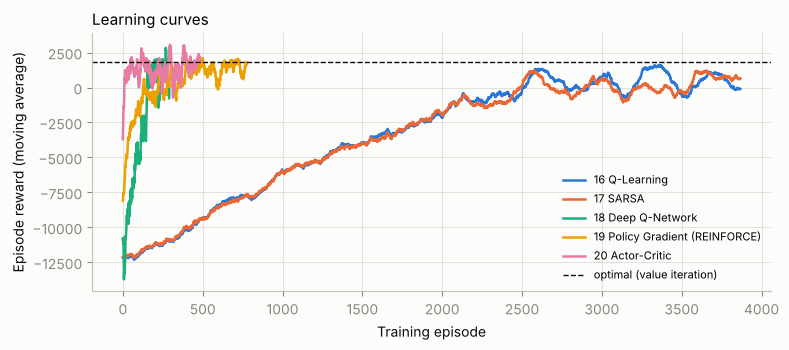

In [23]:
RL_LEARNERS = {
    16: ("Q-Learning", lambda p: train_tabular("q", p, EPISODES["tabular"]), [0.05, 0.1, 0.3]),
    17: ("SARSA", lambda p: train_tabular("sarsa", p, EPISODES["tabular"]), [0.05, 0.1, 0.3]),
}
if TORCH:
    RL_LEARNERS.update({
        18: ("Deep Q-Network", lambda p: train_dqn(p, EPISODES["dqn"]), [1e-3, 3e-3]),
        19: ("Policy Gradient (REINFORCE)", lambda p: train_reinforce(p, EPISODES["pg"]), [3e-3, 1e-2]),
        20: ("Actor-Critic", lambda p: train_actor_critic(p, EPISODES["ac"]), [1e-3, 3e-3]),
    })

rl_rows, curves, policies = [], {}, {}
opt_test = evaluate_policy(POLICY_OPT, TEST_SEEDS)
policies["29 MDP (value iteration)"] = POLICY_OPT
rl_rows.append({"algorithm": "29 MDP (value iteration)", "tuned": "exact", **opt_test})
for num, (name, train_fn, grid) in RL_LEARNERS.items():
    best = None
    t0 = time.perf_counter()
    for p in grid:
        policy, curve = train_fn(p)
        val = evaluate_policy(policy, VAL_SEEDS)["mean_reward"]
        if best is None or val > best[0]:
            best = (val, p, policy, curve)
    label = f"{num:02d} {name}"
    policies[label], curves[label] = best[2], best[3]
    rl_rows.append({"algorithm": label, "tuned": f"{'alpha' if num in (16, 17) else 'lr'}={best[1]}",
                    **evaluate_policy(best[2], TEST_SEEDS), "train_seconds": time.perf_counter() - t0})
    print(f"{label:35s} done ({time.perf_counter() - t0:.0f}s)")

for label, policy in [("baseline: run to failure", np.zeros(N_STATES, int)),
                      ("baseline: replace at >= 200 min", (np.arange(N_STATES) * WEAR_BUCKET >= 200).astype(int))]:
    policies[label] = policy
    rl_rows.append({"algorithm": label, "tuned": "rule", **evaluate_policy(policy, TEST_SEEDS)})

rl_leaderboard = pd.DataFrame(rl_rows).sort_values("mean_reward", ascending=False).reset_index(drop=True)
rl_leaderboard["gap_to_optimal"] = rl_leaderboard.mean_reward - opt_test["mean_reward"]   # 0 = as good as optimal
rl_leaderboard.insert(0, "rank", range(1, len(rl_leaderboard) + 1))
display(rl_leaderboard.round(2))

policy_table = pd.DataFrame({k: ["replace" if a else "run" for a in v] for k, v in policies.items()},
                            index=[f"{b * WEAR_BUCKET}-{(b + 1) * WEAR_BUCKET - 1} min" for b in range(N_STATES)]).T
display(policy_table)

fig, ax = plt.subplots(figsize=(8, 3.6))
for (label, curve), color in zip(curves.items(), PALETTE):
    w = max(1, len(curve) // 30)
    ax.plot(np.convolve(curve, np.ones(w) / w, mode="valid"), color=color, linewidth=1.8, label=label)
ax.axhline(opt_test["mean_reward"], color=INK, linewidth=1, linestyle="--", label="optimal (value iteration)")
ax.set_xlabel("Training episode"); ax.set_ylabel("Episode reward (moving average)"); ax.set_title("Learning curves")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 13 · Summary: all 30 algorithms ranked within their role

Algorithms do different jobs, so a single number across roles would be meaningless. Each is ranked against the others
in **its own stage, on that stage's metric**. The headline outcomes are the selected failure-prediction model
(Section 11) and the best maintenance policy (Section 12).

In [24]:
summary = []
for _, r in leaderboard.iterrows():
    summary.append({"algorithm": r.model, "stage": "Failure prediction", "metric": "CV PR-AUC", "score": r.cv_pr_auc,
                    "rank_in_stage": r["rank"], "note": "SELECTED" if r.num == SELECTED else ("tied with best" if r.tied_with_best else "")})
for _, r in cluster_leaderboard.iterrows():
    summary.append({"algorithm": r.algorithm, "stage": "Clustering", "metric": "silhouette", "score": r.silhouette,
                    "rank_in_stage": r["rank"], "note": r.params})
summary.append({"algorithm": "15 t-SNE", "stage": "Visualisation", "metric": "trustworthiness",
                "score": tsne_table.trustworthiness.max(), "rank_in_stage": 1, "note": f"perplexity {best_perp}"})
summary.append({"algorithm": "30 Genetic Algorithm (selection)", "stage": "Feature selection", "metric": "GA fitness",
                "score": float(fitness.max()), "rank_in_stage": 1, "note": f"{len(GA_FEATURES)}/{len(FEATURES)} features"})
rl_ranked = rl_leaderboard[~rl_leaderboard.algorithm.str.startswith("baseline")].reset_index(drop=True)
for i, r in rl_ranked.iterrows():
    summary.append({"algorithm": r.algorithm, "stage": "Maintenance policy", "metric": "test reward / episode",
                    "score": r.mean_reward, "rank_in_stage": i + 1, "note": f"gap to optimal {r.gap_to_optimal:+,.0f} per episode"})
summary = pd.DataFrame(summary)
summary["num"] = summary.algorithm.str[:2].astype(int)
covered = sorted(set(summary.num))
print(f"Algorithms covered: {len(covered)} / 30", "" if len(covered) == 30 else f"(missing: {sorted(set(range(1, 31)) - set(covered))})")
display(summary.drop(columns="num").round(4))

summary.to_csv(RESULTS_DIR / "all_algorithms_summary.csv", index=False)
leaderboard.to_csv(RESULTS_DIR / "failure_prediction_leaderboard.csv", index=False)
rl_leaderboard.to_csv(RESULTS_DIR / "maintenance_policy_leaderboard.csv", index=False)
cluster_leaderboard.to_csv(RESULTS_DIR / "clustering_leaderboard.csv", index=False)
best_rl = rl_ranked.iloc[0]
print(f"\nData: {'AI4I 2020 (UCI)' if DATA_IS_REAL else 'evaluation sample (documented AI4I process), not the original UCI file'}")
print(f"Selected failure model: {SELECTED:02d} {sel['name']}  test PR-AUC {test_metrics['pr_auc']:.3f}, "
      f"recall {test_metrics['recall']:.2%}, precision {test_metrics['precision']:.2%}, cost per 1000 machines ${test_metrics['cost_per_1000']:,.0f}")
best_learned = rl_ranked[~rl_ranked.algorithm.str.startswith("29")].iloc[0]
print(f"Best learned maintenance policy: {best_learned.algorithm} (gap to the optimal MDP policy: {best_learned.gap_to_optimal:+,.0f} per episode)")

Algorithms covered: 30 / 30 


,algorithm,stage,metric,score,rank_in_stage,note
0,08 Gradient Boosting,Failure prediction,CV PR-AUC,0.8859,1,tied with best
1,09 AdaBoost,Failure prediction,CV PR-AUC,0.8849,2,SELECTED
2,04 Random Forest,Failure prediction,CV PR-AUC,0.8817,3,tied with best
3,10 XGBoost,Failure prediction,CV PR-AUC,0.8797,4,tied with best
4,30 GA-selected features + Random Forest,Failure prediction,CV PR-AUC,0.8797,5,tied with best
5,03 Decision Tree,Failure prediction,CV PR-AUC,0.8356,6,
6,25 Transformer,Failure prediction,CV PR-AUC,0.7541,7,
7,23 Recurrent Neural Network,Failure prediction,CV PR-AUC,0.7413,8,
8,22 Convolutional Neural Network,Failure prediction,CV PR-AUC,0.7340,9,
9,24 Long Short-Term Memory,Failure prediction,CV PR-AUC,0.7281,10,



Data: evaluation sample (documented AI4I process), not the original UCI file
Selected failure model: 09 AdaBoost  test PR-AUC 0.769, recall 74.39%, precision 46.56%, cost per 1000 machines $26,250
Best learned maintenance policy: 20 Actor-Critic (gap to the optimal MDP policy: +0 per episode)


## Notes and next steps

* **Re-run on your plant's data**: replace Section 1 with your own loader using the same column names; every later
  stage adapts automatically.
* **Costs drive the threshold and the policy**: set `COST_FN`, `COST_FP`, `REVENUE`, `FAILURE_COST` and `REPLACE_COST`
  to real figures before acting on the recommendations.
* **Search budget**: raise `N_ITER` / `DL_N_ITER` for more thorough tuning; the corrected t-test tells you whether
  differences between top models are real.
* **Sequence models**: with genuine time series (e.g. sensor histories per machine), feed windows of readings to the
  CNN / RNN / LSTM / Transformer instead of feature tokens; that is where they usually overtake tree ensembles.